# Superstore Retail Analysis Project

## Business Objectives

1. What is the overall sales performance of the business?
2. How does sales performance change over time?
3. Which segments are driving sales, and which have weaker performance?
4. Which products/categories are driving revenue?
5. Are high-volume products necessarily the highest-revenue products?
6. Who are the highest-value customers, and how concentrated is customer revenue?
7. How frequently do customers purchase?
8. Are there meaningful seasonal patterns in sales?

### Loading The Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
superstore = pd.read_csv('train.csv')
superstore.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


### Data Cleaning and Wrangling

In [3]:
superstore.shape

(4822, 18)

In [4]:
superstore.isna().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      1
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64

In [5]:
superstore.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4822 entries, 0 to 4821
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         4822 non-null   int64  
 1   Order ID       4822 non-null   object 
 2   Order Date     4822 non-null   object 
 3   Ship Date      4822 non-null   object 
 4   Ship Mode      4822 non-null   object 
 5   Customer ID    4822 non-null   object 
 6   Customer Name  4822 non-null   object 
 7   Segment        4822 non-null   object 
 8   Country        4822 non-null   object 
 9   City           4822 non-null   object 
 10  State          4822 non-null   object 
 11  Postal Code    4821 non-null   float64
 12  Region         4822 non-null   object 
 13  Product ID     4822 non-null   object 
 14  Category       4822 non-null   object 
 15  Sub-Category   4822 non-null   object 
 16  Product Name   4822 non-null   object 
 17  Sales          4822 non-null   float64
dtypes: float

In [6]:
superstore["Order Date"] = pd.to_datetime(superstore["Order Date"], dayfirst = True)

In [7]:
superstore.describe()

,Row ID,Order Date,Postal Code,Sales
count,4822.000000,4822,4821.000000,4822.000000
mean,2411.500000,2017-04-24 05:34:45.939444224,54907.867040,229.168572
min,1.000000,2015-01-04 00:00:00,1040.000000,0.444000
25%,1206.250000,2016-05-17 00:00:00,22304.000000,16.768000
50%,2411.500000,2017-06-04 00:00:00,55122.000000,52.596000
75%,3616.750000,2018-05-13 00:00:00,90004.000000,212.033500
max,4822.000000,2018-12-30 00:00:00,99207.000000,22638.480000
std,1392.135829,NaN,31816.476215,637.194491


In [8]:
superstore.isna().sum().sort_values(ascending=False)

Postal Code      1
Row ID           0
Order ID         0
Order Date       0
Ship Mode        0
Ship Date        0
Customer Name    0
Segment          0
Country          0
Customer ID      0
City             0
State            0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64

In [9]:
duplicate = superstore[superstore.iloc[:,1:].duplicated(keep=False)]
duplicate

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
3405,3406,US-2015-150119,2015-04-23,27/04/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229.0,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372
3406,3407,US-2015-150119,2015-04-23,27/04/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229.0,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372


In [10]:
superstore = superstore.drop_duplicates(
    subset=superstore.columns[1:],
    keep="first"
)

| Measure | Definition | Use |
|---|---|---|
| Sales | Sum of the `Sales` column | Revenue performance |
| Orders | Distinct `Order ID` count | Order activity |
| Customers | Distinct `Customer ID` count | Customer reach |
| Sales per order | Sales divided by distinct orders | Average order value |
| Product order count | Distinct orders containing a product | Rough demand proxy |

### Overall Sales Performance

In [11]:
sales = superstore['Sales'].sum()
orders_count = superstore['Order ID'].nunique()
customers_count = superstore['Customer ID'].nunique()
sales_per_order = sales/orders_count
sales_per_customer = sales/customers_count

### Sales Over Time

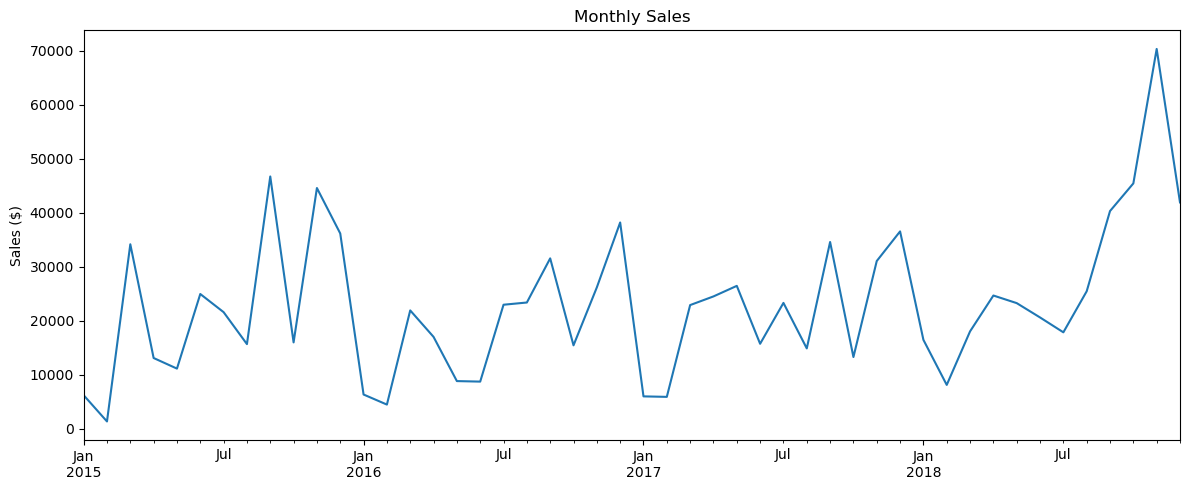

In [12]:
monthly_sales = (
    superstore.set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
)
monthly_sales.plot(figsize=(12, 5), title="Monthly Sales")
plt.ylabel("Sales ($)")
plt.xlabel("")
plt.tight_layout()
plt.show()

### 3 Month Rolling Average

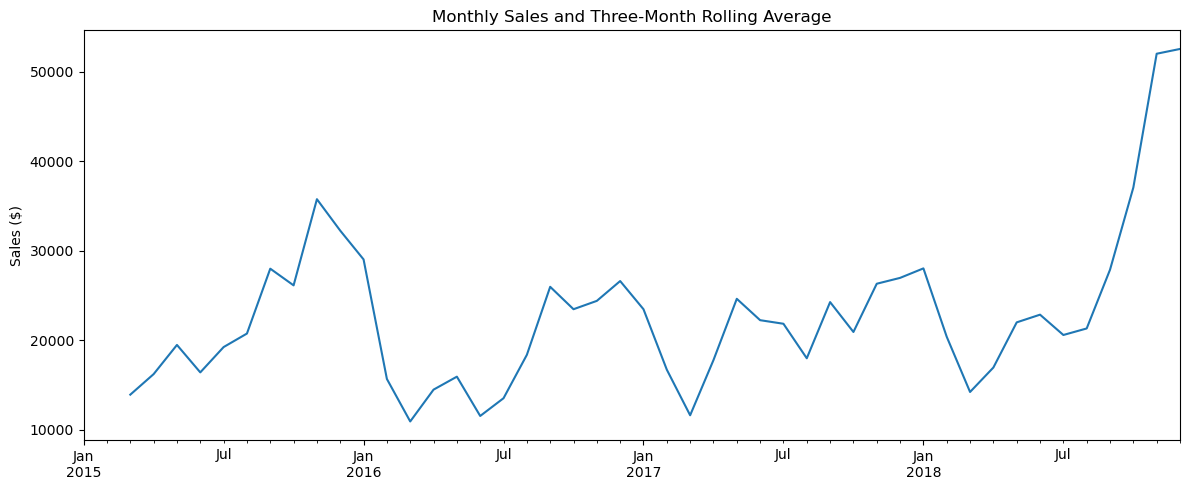

In [13]:
monthly_sales.rolling(3).mean().plot(
    figsize=(12, 5),
    title="Monthly Sales and Three-Month Rolling Average"
)
plt.ylabel("Sales ($)")
plt.xlabel("")
plt.tight_layout()
plt.show()

### Sales by Conusmer Segment

In [14]:
segment_summary = (superstore.groupby('Segment').agg(sales = ('Sales','sum'), 
                                                  orders = ('Order ID', 'nunique'),
                                                  customers = ('Customer ID', 'nunique')))
segment_summary["sales_per_order"] = (
    segment_summary["sales"] / segment_summary["orders"]
)

segment_summary.sort_values("sales", ascending=False)

,sales,orders,customers,sales_per_order
Segment,,,,
Consumer,560511.2539,1271,394,441.000200
Corporate,314387.0533,682,219,460.978084
Home Office,229871.1735,434,140,529.657082


### Categories and Products Driving Revenue

In [15]:
category_sales = (
    superstore.groupby(["Category", "Sub-Category"]).agg(sales = ('Sales','sum'), orders = ('Order ID', 'nunique'))
)

category_sales["sales_per_order"] = (
    category_sales["sales"] / category_sales["orders"]
)

category_sales.sort_values("sales_per_order", ascending=False)

sales  orders  sales_per_order
Category        Sub-Category                                      
Technology      Machines      118103.4710      55      2147.335836
                Copiers        61809.1340      32      1931.535438
Furniture       Tables        100505.3640     150       670.035760
                Chairs        146739.4180     266       551.651947
                Bookcases      49620.0337     104       477.115709
Technology      Phones        164609.2580     396       415.679944
Office Supplies Supplies       27173.6720      84       323.496095
                Storage       111364.5200     375       296.972053
                Appliances     49069.8650     203       241.723473
Technology      Accessories    77080.5380     341       226.042633
Office Supplies Binders        86014.2390     637       135.030203
Furniture       Furnishings    45062.1220     416       108.322409
Office Supplies Envelopes       8612.7940     124        69.458016
                Paper          37882.8920     569        66.578018
                Labels          6028.3260     161        37.443019
                Art            13433.4080     363        37.006634
                Fasteners       1660.4260     116        14.314017

In [16]:
product_sales = (
    superstore.groupby(["Product ID", "Product Name"]).agg(sales = ('Sales','sum'), orders = ('Order ID', 'nunique'))
)
product_sales["sales_per_order"] = (
    product_sales["sales"] / product_sales["orders"]
)
sorted_product_sales = product_sales.sort_values("sales_per_order", ascending=False)
sorted_product_sales.head(10)

,,sales,orders,sales_per_order
Product ID,Product Name,,,
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,1,22638.48000
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,21699.938,2,10849.96900
OFF-BI-10001120,Ibico EPK-21 Electric Binding System,9449.950,1,9449.95000
TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930,1,9099.93000
OFF-SU-10000151,High Speed Automatic Electric Letter Opener,8187.650,1,8187.65000
TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.980,1,7999.98000
TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,4899.930,1,4899.93000
TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.901,4,4207.47525
TEC-MA-10002927,Canon imageCLASS MF7460 Monochrome Digital Laser Multifunction Copier,3991.980,1,3991.98000


In [17]:
products_by_orders = product_sales.sort_values("orders", ascending=False)

products_by_orders.head(10)

,,sales,orders,sales_per_order
Product ID,Product Name,,,
TEC-AC-10003628,Logitech 910-002974 M325 Wireless Mouse for Web Scrolling,1121.626,11,101.966000
OFF-ST-10000736,Carina Double Wide Media Storage Towers in Natural & Black,1813.952,10,181.395200
OFF-ST-10004804,"Belkin 19"" Vented Equipment Shelf, Black",1400.256,10,140.025600
FUR-CH-10000785,Global Ergonomic Managers Chair,4705.480,9,522.831111
OFF-BI-10004970,"ACCOHIDE 3-Ring Binder, Blue, 1""",99.120,9,11.013333
OFF-BI-10000546,Avery Durable Binders,73.728,9,8.192000
FUR-CH-10002647,"Situations Contoured Folding Chairs, 4/Set",2122.302,8,265.287750
OFF-ST-10001809,Fellowes Officeware Wire Shelving,3162.016,8,395.252000
FUR-CH-10002965,"Global Leather Highback Executive Chair with Pneumatic Height Adjustment, Black",3939.208,8,492.401000


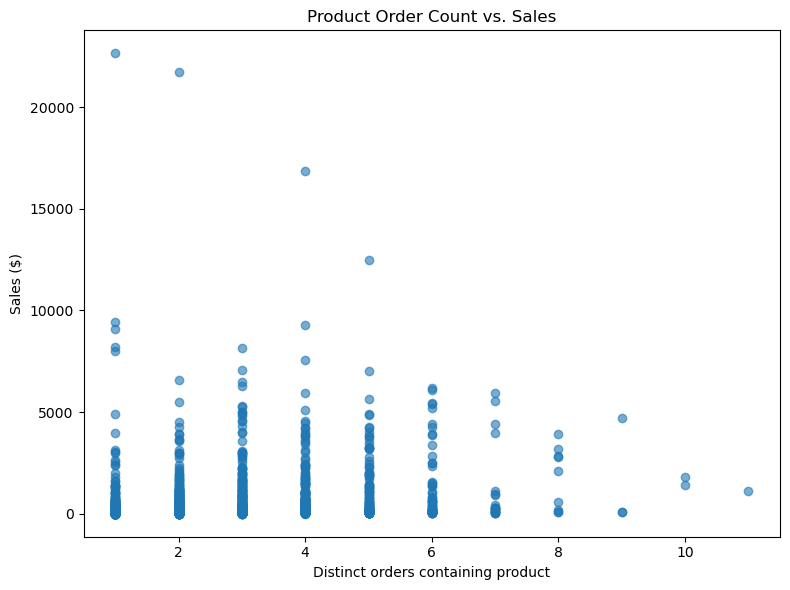

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(product_sales["orders"], product_sales["sales"], alpha=0.6)
ax.set(
    title="Product Order Count vs. Sales",
    xlabel="Distinct orders containing product",
    ylabel="Sales ($)"
)
plt.tight_layout()
plt.show()

### Valuable Customers

In [19]:
customer_sales = superstore.groupby(["Customer ID", "Customer Name"])["Sales"].sum().sort_values(ascending = False)
customer_sales.head(10)

Customer ID  Customer Name 
SM-20320     Sean Miller       24195.646
KL-16645     Ken Lonsdale      13956.937
TA-21385     Tom Ashbrook      13716.458
HL-15040     Hunter Lopez      12873.298
SC-20095     Sanjit Chand      12037.794
BM-11140     Becky Martin      11150.924
BS-11365     Bill Shonely      10022.293
GT-14635     Grant Thornton     9351.212
KD-16270     Karen Daniels      7956.658
SB-20290     Sean Braxton       7792.031
Name: Sales, dtype: float64

#### How much Revenue comes from top 10% of customers

In [20]:
top_10_percent_count = max(1, int(len(customer_sales) * 0.10))
top_10_percent_sales = customer_sales.head(top_10_percent_count).sum()
revenue_share = top_10_percent_sales / customer_sales.sum()

print(f"Top 10% of customers' revenue share: {revenue_share:.1%}")

Top 10% of customers' revenue share: 38.7%


### Purchase Frequency

In [25]:
orders_per_customer = superstore.groupby(["Customer ID", "Customer Name"])["Order ID"].nunique()
orders_per_customer.describe()

count    753.000000
mean       3.169987
std        1.667206
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       11.000000
Name: Order ID, dtype: float64

In [28]:
customer_order_dates = (superstore[["Customer ID", "Order ID", "Order Date"]].drop_duplicates()
                       .sort_values(["Customer ID", "Order Date"])
                       )

customer_order_dates["days_since_previous_order"] = (
    customer_order_dates.groupby("Customer ID")["Order Date"]
      .diff()
      .dt.days
)

customer_order_dates["days_since_previous_order"].describe()

count    1634.000000
mean      297.050184
std       262.528568
min         0.000000
25%        92.000000
50%       222.500000
75%       430.000000
max      1347.000000
Name: days_since_previous_order, dtype: float64

### Seasonality

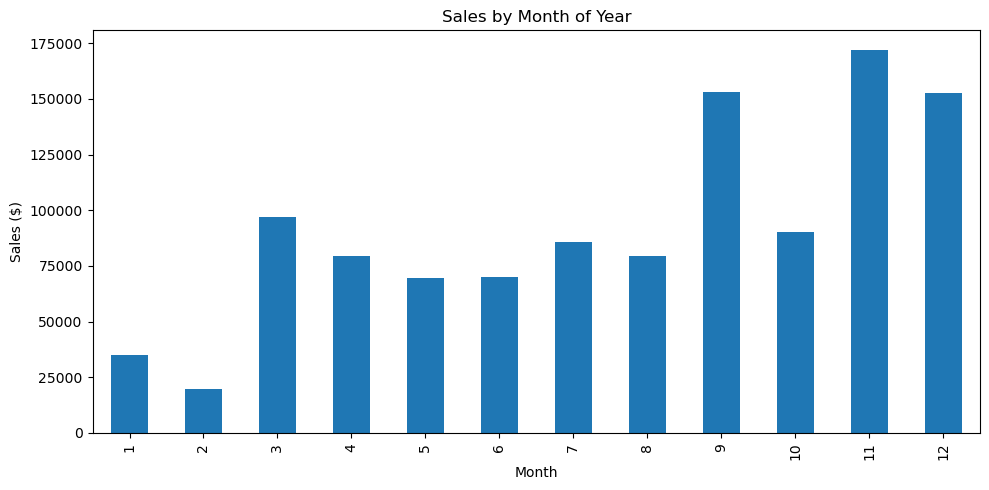

In [30]:
superstore["Month"] = superstore["Order Date"].dt.month

monthly_seasonality = (
    superstore.groupby("Month")["Sales"]
      .sum()
      .reindex(range(1, 13))
)

monthly_seasonality.plot(
    kind="bar",
    figsize=(10, 5),
    title="Sales by Month of Year"
)
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

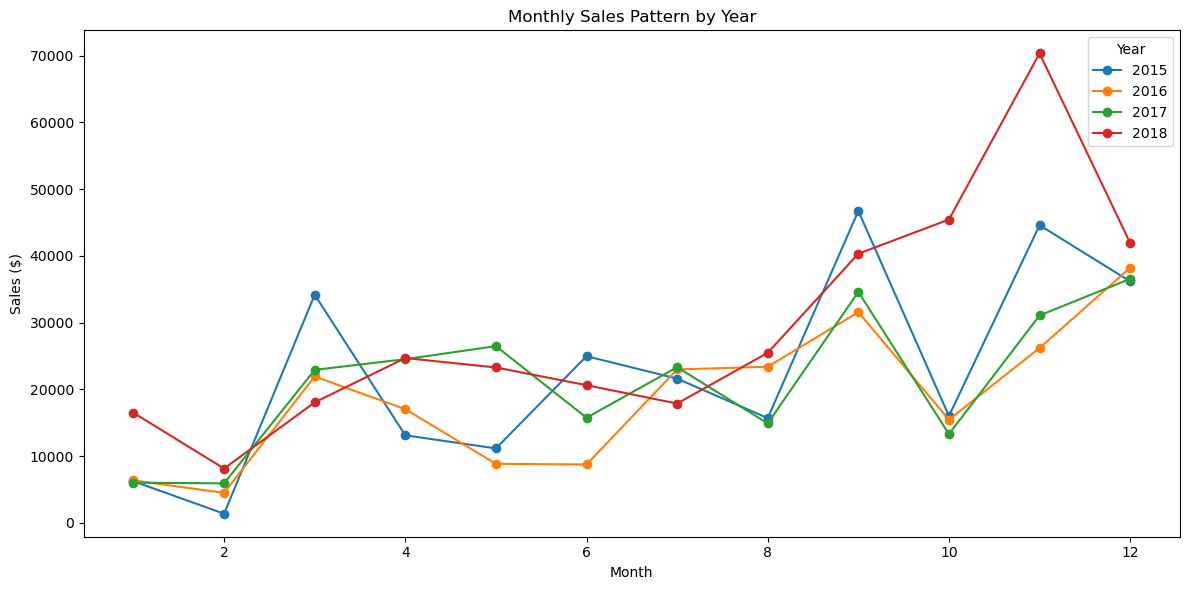

In [31]:
superstore["Year"] = superstore["Order Date"].dt.year
superstore["Month Number"] = superstore["Order Date"].dt.month

year_month_sales = superstore.pivot_table(
    index="Month Number",
    columns="Year",
    values="Sales",
    aggfunc="sum"
)

year_month_sales.plot(figsize=(12, 6), marker="o")
plt.title("Monthly Sales Pattern by Year")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()